In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import os
from pathlib import Path


In [3]:
# Identify project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Load extracted features
csv_path = project_dir / "results" / "features.csv"

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (1537, 12)


,filename,Mean,Std,RMS,Variance,Maximum,Minimum,Peak_to_Peak,Skewness,Kurtosis,Crest_Factor,Label
0,100.mat,0.012531,0.066419,0.067591,0.004411,0.225305,-0.209450,0.434754,-0.075924,-0.105605,3.333365,Normal
1,100.mat,0.012378,0.064499,0.065676,0.004160,0.221967,-0.190674,0.412641,-0.129917,-0.159895,3.379705,Normal
2,100.mat,0.013284,0.062348,0.063747,0.003887,0.181287,-0.172525,0.353812,-0.041127,-0.199957,2.843829,Normal
3,100.mat,0.011395,0.063954,0.064961,0.004090,0.194638,-0.209450,0.404088,-0.191118,-0.091529,3.224227,Normal
4,100.mat,0.011194,0.065106,0.066062,0.004239,0.228434,-0.195055,0.423489,-0.047134,-0.003992,3.457885,Normal


In [4]:
# Define input features
features = [
    "Mean",
    "Std",
    "RMS",
    "Variance",
    "Maximum",
    "Minimum",
    "Peak_to_Peak",
    "Skewness",
    "Kurtosis",
    "Crest_Factor"
]

# Input variables
X = df[features]

# Target variable
y = df["Label"]

print("Input features shape:", X.shape)
print("Target labels shape:", y.shape)

Input features shape: (1537, 10)
Target labels shape: (1537,)


In [5]:
print("Target classes:")
print(y.value_counts())

print("\nUnique classes:")
print(y.unique())

Target classes:
Label
Normal              828
Inner Race Fault    237
Ball Fault          236
Outer Race Fault    236
Name: count, dtype: int64

Unique classes:
<StringArray>
['Normal', 'Inner Race Fault', 'Ball Fault', 'Outer Race Fault']
Length: 4, dtype: str


In [6]:
from sklearn.preprocessing import LabelEncoder

# Create encoder
label_encoder = LabelEncoder()

# Convert categorical labels into numerical labels
y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded labels:")
print(np.unique(y_encoded))

Original classes:
['Ball Fault' 'Inner Race Fault' 'Normal' 'Outer Race Fault']

Encoded labels:
[0 1 2 3]


In [7]:
from sklearn.model_selection import train_test_split

In [8]:
# Get one label for each original MATLAB recording
file_labels = df[["filename", "Label"]].drop_duplicates()

print("Total original recordings:", len(file_labels))

print("\nRecordings per class:")
print(file_labels["Label"].value_counts())

Total original recordings: 16

Recordings per class:
Label
Normal              4
Inner Race Fault    4
Ball Fault          4
Outer Race Fault    4
Name: count, dtype: int64


In [9]:
# Split original filenames, not individual segments
train_files, test_files = train_test_split(
    file_labels["filename"],
    test_size=0.25,
    random_state=42,
    stratify=file_labels["Label"]
)

print("Training recordings:", len(train_files))
print("Testing recordings:", len(test_files))

Training recordings: 12
Testing recordings: 4


In [10]:
# Identify rows belonging to training recordings
train_mask = df["filename"].isin(train_files)

# Identify rows belonging to testing recordings
test_mask = df["filename"].isin(test_files)

# Split input features
X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

# Split encoded target labels
y_train = pd.Series(
    y_encoded,
    index=df.index
).loc[train_mask]

y_test = pd.Series(
    y_encoded,
    index=df.index
).loc[test_mask]

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (1124, 10)
Testing feature shape: (413, 10)
Training target shape: (1124,)
Testing target shape: (413,)


In [11]:
# Check whether any filename exists in both datasets
common_files = set(train_files).intersection(set(test_files))

print("Common recordings:", common_files)

if len(common_files) == 0:
    print("SUCCESS: No data leakage detected!")
else:
    print("ERROR: Data leakage detected!")

Common recordings: set()
SUCCESS: No data leakage detected!


In [12]:
print("Training class distribution:")
print(df.loc[train_mask, "Label"].value_counts())

print("\nTesting class distribution:")
print(df.loc[test_mask, "Label"].value_counts())

Training class distribution:
Label
Normal              592
Inner Race Fault    178
Ball Fault          177
Outer Race Fault    177
Name: count, dtype: int64

Testing class distribution:
Label
Normal              236
Inner Race Fault     59
Ball Fault           59
Outer Race Fault     59
Name: count, dtype: int64


In [13]:
from sklearn.ensemble import RandomForestClassifier

In [14]:
# Initialize Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced_subsample",
    min_samples_leaf=2,
    n_jobs=-1
)

print("Random Forest model initialized successfully!")

Random Forest model initialized successfully!


In [15]:
# Train Random Forest using training data

rf_model.fit(X_train, y_train)

print("Random Forest training completed successfully!")

Random Forest training completed successfully!


In [16]:
print("Number of Decision Trees:", len(rf_model.estimators_))

print("\nModel classes:")
print(label_encoder.inverse_transform(rf_model.classes_))

print("\nNumber of training samples:", len(X_train))
print("Number of testing samples:", len(X_test))

Number of Decision Trees: 300

Model classes:
['Ball Fault' 'Inner Race Fault' 'Normal' 'Outer Race Fault']

Number of training samples: 1124
Number of testing samples: 413


In [17]:
# Generate predictions on unseen testing data

y_pred = rf_model.predict(X_test)

print("Predictions generated successfully!")

print("\nFirst 20 actual labels:")
print(label_encoder.inverse_transform(y_test[:20]))

print("\nFirst 20 predicted labels:")
print(label_encoder.inverse_transform(y_pred[:20]))

Predictions generated successfully!

First 20 actual labels:
['Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault']

First 20 predicted labels:
['Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault' 'Inner Race Fault'
 'Inner Race Fault' 'Inner Race Fault']


In [18]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

Model Accuracy: 100.0 %


In [19]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                  precision    recall  f1-score   support

      Ball Fault       1.00      1.00      1.00        59
Inner Race Fault       1.00      1.00      1.00        59
          Normal       1.00      1.00      1.00       236
Outer Race Fault       1.00      1.00      1.00        59

        accuracy                           1.00       413
       macro avg       1.00      1.00      1.00       413
    weighted avg       1.00      1.00      1.00       413



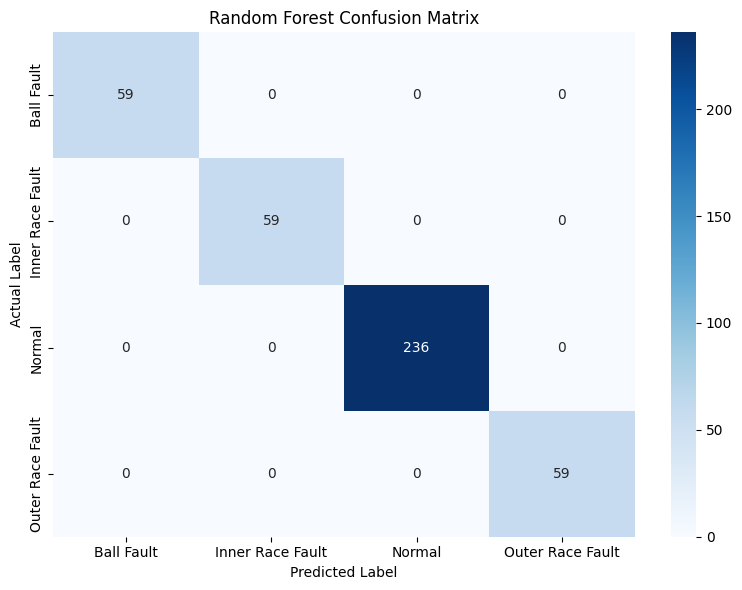

In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.savefig(
    project_dir / "results" / "eda" / "graphs" / "random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier
import numpy as np

In [22]:
X = df[features]
y = np.array(y_encoded)
groups = df["filename"].values

sgkf = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

In [23]:
fold_accuracies = []

for fold, (train_idx, val_idx) in enumerate(
    sgkf.split(X, y, groups), start=1
):

    X_train_fold = X.iloc[train_idx]
    X_val_fold = X.iloc[val_idx]

    y_train_fold = y[train_idx]
    y_val_fold = y[val_idx]

    # Create a fresh model for every fold
    model = RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced_subsample",
        min_samples_leaf=2,
        n_jobs=-1
    )

    # Train
    model.fit(X_train_fold, y_train_fold)

    # Predict
    y_pred_fold = model.predict(X_val_fold)

    # Calculate accuracy
    accuracy = accuracy_score(y_val_fold, y_pred_fold)

    fold_accuracies.append(accuracy)

    print(f"Fold {fold} Accuracy: {accuracy * 100:.2f}%")

print("\nAverage Cross-Validation Accuracy:",
      np.mean(fold_accuracies) * 100, "%")

print("Standard Deviation:",
      np.std(fold_accuracies) * 100, "%")

Fold 1 Accuracy: 100.00%
Fold 2 Accuracy: 100.00%
Fold 3 Accuracy: 100.00%
Fold 4 Accuracy: 100.00%

Average Cross-Validation Accuracy: 100.0 %
Standard Deviation: 0.0 %


In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importance = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": importance
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df)

        Feature    Importance
5       Minimum  1.712466e-01
1           Std  1.544395e-01
4       Maximum  1.478132e-01
2           RMS  1.422093e-01
3      Variance  1.390972e-01
6  Peak_to_Peak  1.344606e-01
8      Kurtosis  1.066667e-01
9  Crest_Factor  4.048489e-03
7      Skewness  1.846722e-05
0          Mean  1.047064e-15


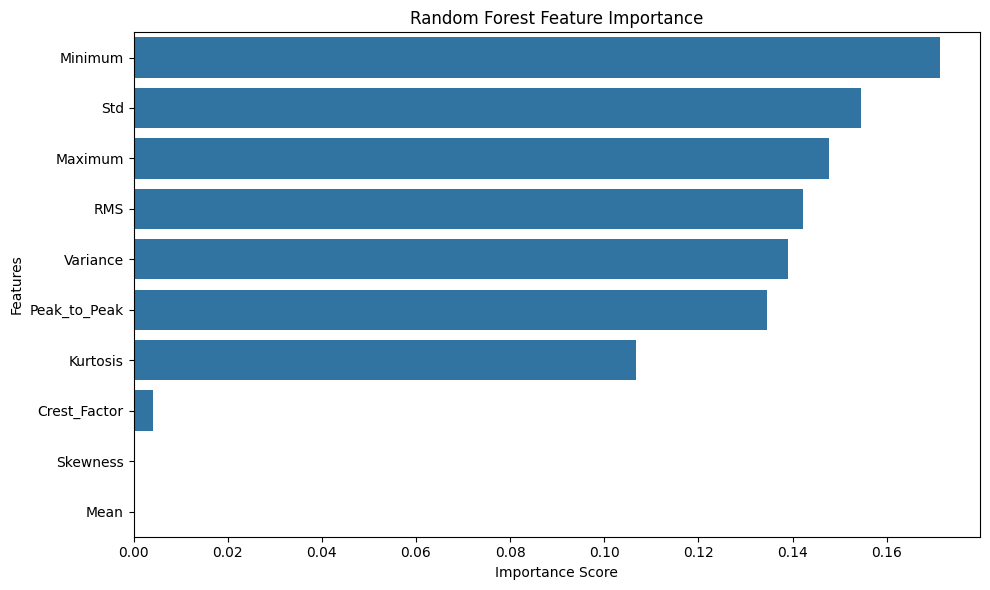

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()